<a href="https://colab.research.google.com/github/Jozen1/EntregasGO_Equipo8/blob/main/notebooks/Avance1A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
# Clona el repositorio 'Operations-Management' de GitHub en el entorno actual.
!git clone https://github.com/LuisRojo-Gonzalez/Operations-Management.git

fatal: destination path 'Operations-Management' already exists and is not an empty directory.


In [43]:
# Muestra la ruta del directorio de trabajo actual.
!pwd

/content


# **Importación de librerías**

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [45]:
# Fijar semilla global para garantizar 100% de reproducibilidad
SEED = 42
np.random.seed(SEED)

In [46]:
# Cargar datasets principales
d_llenado = pd.read_csv('/content/Operations-Management/CaseStudy/Datos/calidad_llenado.csv')
specs = pd.read_csv('/content/Operations-Management/CaseStudy/Datos/especificaciones_calidad.csv')
d_atributos = pd.read_csv('/content/Operations-Management/CaseStudy/Datos/calidad_atributos.csv')
maestro_sku = pd.read_csv('/content/Operations-Management/CaseStudy/Datos/maestro_sku.csv')

# **Definición de parámetros y costos**

In [47]:
# Cargar demanda semanal histórica para calcular la demanda anual real por formato
d_demanda = pd.read_csv('/content/Operations-Management/CaseStudy/Datos/demanda_semanal.csv')

# Unir con maestro_sku para mapear cada SKU a su formato y costo
d_demanda = d_demanda.merge(maestro_sku[['sku', 'formato_L', 'costo_variable_caja_clp', 'botellas_por_caja']], on='sku')

# Demanda anual promedio en cajas por formato (156 semanas equivale a 3 años)
demanda_anual_por_formato = d_demanda.groupby('formato_L')['ventas_cajas'].sum() / 3.0

# Costo variable promedio por litro según formato (Costo caja CLP / Litros totales por caja)
maestro_sku['litros_caja'] = maestro_sku['botellas_por_caja'] * maestro_sku['formato_L']
maestro_sku['costo_por_litro'] = maestro_sku['costo_variable_caja_clp'] / maestro_sku['litros_caja']
costo_litro_por_formato = maestro_sku.groupby('formato_L')['costo_por_litro'].mean()

# Unidades por caja según formato
# Cargar unidades por caja directamente desde maestro_sku (sin escribir números a mano)
unidades_caja = maestro_sku.groupby('formato_L')['botellas_por_caja'].first().to_dict()

# Constantes de control para subgrupos de n = 5 (Carta X-bar - R)
d2 = 2.326
A2 = 0.577
D3 = 0.0
D4 = 2.114

# Separación en Fase I (Semanas <= 8) y Fase II (Semanas > 8)
FASE_1_MAX_WEEK = 8

# **Control estadístico por variables (X - R) y capacidad de proceso**

In [48]:
resumen_global = []
resumen_turnos = []

for (linea, formato), df_group in d_llenado.groupby(['linea', 'formato_L']):
    # Obtener especificaciones del producto
    sp = specs[specs['formato_L'] == formato].iloc[0]
    nominal = sp['nominal_mL']
    tol = sp['tolerancia_oiml_mL']
    lci_legal = sp['limite_legal_inferior_mL']
    LES = nominal + tol
    LEI = nominal - tol

    # Separar datos en Fase I y Fase II
    fase1 = df_group[df_group['semana_registro'] <= FASE_1_MAX_WEEK]
    fase2 = df_group[df_group['semana_registro'] > FASE_1_MAX_WEEK]

    # --- FASE I: ESTIMACIÓN Y DEPURACIÓN DE LÍMITES (SIN LEAKAGE) ---
    sub_fase1 = fase1.groupby('subgrupo')['volumen_mL'].agg(['mean', lambda x: x.max() - x.min()])
    sub_fase1.columns = ['X_bar', 'R']

    # 1. Estimación preliminar
    X_double_bar_pre = sub_fase1['X_bar'].mean()
    R_bar_pre = sub_fase1['R'].mean()

    LCS_X_pre = X_double_bar_pre + A2 * R_bar_pre
    LCI_X_pre = X_double_bar_pre - A2 * R_bar_pre
    LCS_R_pre = D4 * R_bar_pre
    LCI_R_pre = D3 * R_bar_pre

    # 2. Filtrar subgrupos limpios en Fase I (eliminación de causas asignables)
    sub_fase1_limpio = sub_fase1[
        (sub_fase1['X_bar'] <= LCS_X_pre) & (sub_fase1['X_bar'] >= LCI_X_pre) &
        (sub_fase1['R'] <= LCS_R_pre) & (sub_fase1['R'] >= LCI_R_pre)
    ]

    # 3. Límites CONGELADOS definitivos con Fase I limpia
    X_double_bar = sub_fase1_limpio['X_bar'].mean()
    R_bar = sub_fase1_limpio['R'].mean()

    LCS_X = X_double_bar + A2 * R_bar
    LCI_X = X_double_bar - A2 * R_bar
    LCS_R = D4 * R_bar
    LCI_R = D3 * R_bar

    # --- FASE II: MONITOREO DE CARTAS X-bar Y R ---
    sub_fase2 = fase2.groupby('subgrupo')['volumen_mL'].agg(['mean', lambda x: x.max() - x.min()])
    sub_fase2.columns = ['X_bar', 'R']

    senales_fase2_X = ((sub_fase2['X_bar'] > LCS_X) | (sub_fase2['X_bar'] < LCI_X)).sum()
    senales_fase2_R = ((sub_fase2['R'] > LCS_R) | (sub_fase2['R'] < LCI_R)).sum()

    # --- ESTIMACIÓN DE CAPACIDAD Y DESEMPEÑO (GLOBAL) ---
    sigma_c = R_bar / d2  # Corto plazo (Fase I limpia)
    sigma_p = fase1['volumen_mL'].std()  # Largo plazo (Fase I)

    Cp = (LES - LEI) / (6 * sigma_c)
    Cpk = min((LES - X_double_bar) / (3 * sigma_c), (X_double_bar - LEI) / (3 * sigma_c))

    Pp = (LES - LEI) / (6 * sigma_p)
    Ppk = min((LES - X_double_bar) / (3 * sigma_p), (X_double_bar - LEI) / (3 * sigma_p))

    # Test de Normalidad (Shapiro-Wilk)
    _, p_val_norm = stats.shapiro(sub_fase1['X_bar'])
    es_normal = "Sí" if p_val_norm > 0.05 else "No"

    # Verificación de Límite Legal Inferior
    cumple_legal = "Sí" if X_double_bar >= lci_legal else "NO (VIOLACIÓN LEGAL)"

    # Sobrellenado medio
    sobrellenado_mL = max(0.0, X_double_bar - nominal)

    # Calcular unidades por caja desde maestro_sku (sin hardcodeo)
    sku_formato = maestro_sku[maestro_sku['formato_L'] == formato].iloc[0]
    unid_caja = sku_formato['botellas_por_caja']
    litros_extra_caja = (sobrellenado_mL / 1000.0) * unid_caja

    resumen_global.append({
        'Línea': linea,
        'Formato(L)': formato,
        'X_bar': round(X_double_bar, 2),
        'LCS_X': round(LCS_X, 2),
        'LCI_X': round(LCI_X, 2),
        'LCS_R': round(LCS_R, 2),
        'Cp': round(Cp, 3),
        'Cpk': round(Cpk, 3),
        'Pp': round(Pp, 3),
        'Ppk': round(Ppk, 3),
        'Normalidad(p-val)': f"{round(p_val_norm, 3)} ({es_normal})",
        'Cumple_Legal': cumple_legal,
        'Sobrellenado(mL)': round(sobrellenado_mL, 3),
        'Litros_Extra_Caja': round(litros_extra_caja, 4),
        'Alertas_X_Fase2': senales_fase2_X,
        'Alertas_R_Fase2': senales_fase2_R
    })

    # --- CAPACIDAD DESAGREGADA POR TURNO ---
    for turno, df_turno in fase1.groupby('turno'):
        sub_t = df_turno.groupby('subgrupo')['volumen_mL'].agg(['mean', lambda x: x.max() - x.min()])
        sub_t.columns = ['X_bar', 'R']
        X_bar_t = sub_t['X_bar'].mean()
        R_bar_t = sub_t['R'].mean()
        sigma_c_t = R_bar_t / d2
        sigma_p_t = df_turno['volumen_mL'].std()

        Cp_t = (LES - LEI) / (6 * sigma_c_t)
        Cpk_t = min((LES - X_bar_t) / (3 * sigma_c_t), (X_bar_t - LEI) / (3 * sigma_c_t))
        Pp_t = (LES - LEI) / (6 * sigma_p_t)
        Ppk_t = min((LES - X_bar_t) / (3 * sigma_p_t), (X_bar_t - LEI) / (3 * sigma_p_t))

        resumen_turnos.append({
            'Línea': linea,
            'Formato(L)': formato,
            'Turno': turno,
            'X_bar': round(X_bar_t, 2),
            'Cp': round(Cp_t, 3),
            'Cpk': round(Cpk_t, 3),
            'Pp': round(Pp_t, 3),
            'Ppk': round(Ppk_t, 3)
        })

df_resumen_global = pd.DataFrame(resumen_global)
df_resumen_turnos = pd.DataFrame(resumen_turnos)

In [49]:
print("Tabla resumen global de capacidad y control por variables:\n")
print(df_resumen_global.to_string(index=False))

Tabla resumen global de capacidad y control por variables:

Línea  Formato(L)   X_bar   LCS_X   LCI_X  LCS_R    Cp   Cpk    Pp   Ppk Normalidad(p-val) Cumple_Legal  Sobrellenado(mL)  Litros_Extra_Caja  Alertas_X_Fase2  Alertas_R_Fase2
   L1         0.5  503.60  506.44  500.77  10.39 2.367 1.799 1.913 1.454          0.0 (No)           Sí             3.602             0.0432                5                0
   L2         1.5 1504.48 1511.14 1497.83  24.39 1.512 1.211 1.369 1.096        0.001 (No)           Sí             4.482             0.0269                3                2
   L2         3.0 3008.44 3019.83 2997.05  41.74 1.767 1.436 1.701 1.382        0.092 (Sí)           Sí             8.442             0.0338                0                1


In [50]:
print("\nTabla de capacidad desagregada por turno:\n")
print(df_resumen_turnos.to_string(index=False))


Tabla de capacidad desagregada por turno:

Línea  Formato(L)     Turno   X_bar    Cp   Cpk    Pp   Ppk
   L1         0.5 A (06-14)  503.60 2.361 1.794 1.911 1.452
   L1         0.5 B (14-22)  503.81 2.443 1.822 1.916 1.429
   L2         1.5 A (06-14) 1503.17 1.668 1.433 1.661 1.427
   L2         1.5 B (14-22) 1503.51 1.611 1.360 1.661 1.402
   L2         1.5 C (22-06) 1506.97 1.235 0.853 1.216 0.839
   L2         3.0 A (06-14) 3007.53 1.784 1.486 1.760 1.466
   L2         3.0 B (14-22) 3007.64 1.904 1.581 1.890 1.569
   L2         3.0 C (22-06) 3010.74 1.526 1.162 1.532 1.166


# **Control por atributos, Tasa de merma y Pareto**

In [51]:
# Tasa de merma efectiva por línea (rho_l)
merma_linea = d_atributos.groupby('linea').apply(
    lambda x: x['n_defectuosas'].sum() / x['n_inspeccionadas'].sum(),
    include_groups=False
).reset_index(name='rho_l')

print("Tasa de merma efectiva por línea:\n")
print(merma_linea.to_string(index=False))


Tasa de merma efectiva por línea:

linea    rho_l
   L1 0.019217
   L2 0.031146


In [52]:
# Carta p global
p_bar = d_atributos['n_defectuosas'].sum() / d_atributos['n_inspeccionadas'].sum()
d_atributos['LCS_p'] = p_bar + 3 * np.sqrt(p_bar * (1 - p_bar) / d_atributos['n_inspeccionadas'])
d_atributos['LCI_p'] = np.maximum(0, p_bar - 3 * np.sqrt(p_bar * (1 - p_bar) / d_atributos['n_inspeccionadas']))

# Calcular proporción observada para evaluar puntos fuera de control
p_observada = d_atributos['n_defectuosas'] / d_atributos['n_inspeccionadas']
d_atributos['fuera_control'] = (p_observada > d_atributos['LCS_p']) | (p_observada < d_atributos['LCI_p'])


In [53]:
print(f"\nProporción media global de defectuosos (p_bar): {p_bar:.4f}")


Proporción media global de defectuosos (p_bar): 0.0278


In [54]:
print(f"Puntos fuera de control en Carta p: {d_atributos['fuera_control'].sum()}")

Puntos fuera de control en Carta p: 12


In [55]:
# Diagrama de Pareto de Causas de Defectos
par = d_atributos.groupby('causa_principal')['n_defectuosas'].sum().sort_values(ascending=False)
df_pareto = pd.DataFrame({'Frecuencia': par})
df_pareto['% del Total'] = (100 * df_pareto['Frecuencia'] / par.sum()).round(1)
df_pareto['% Acumulado'] = (100 * par.cumsum() / par.sum()).round(1)

In [56]:
print("Tabla de Pareto de causas de defecto:\n")
print(df_pareto)

Tabla de Pareto de causas de defecto:

                  Frecuencia  % del Total  % Acumulado
causa_principal                                       
Etiqueta                 440         34.5         34.5
Sello/tapa               344         27.0         61.5
Nivel de llenado         324         25.4         86.9
Envase deformado          92          7.2         94.1
Cuerpo extranio           75          5.9        100.0
Sin defectos               0          0.0        100.0


# **Generación de gráficos**

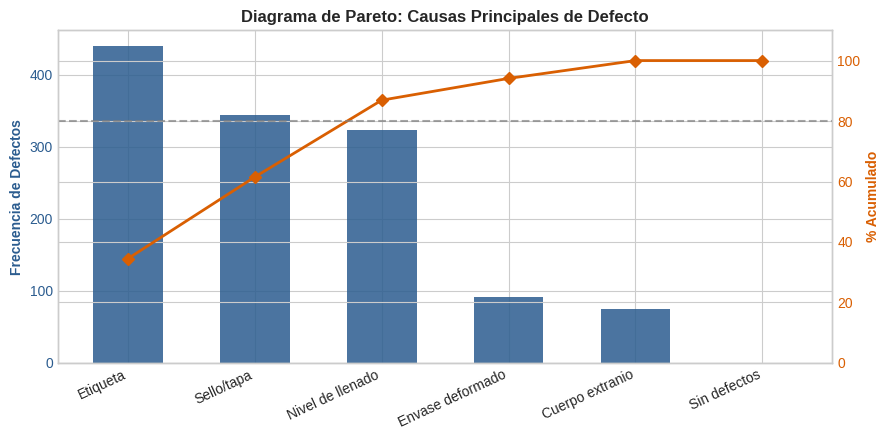

In [57]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 5.1 Graficar Diagrama de Pareto
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(df_pareto.index, df_pareto['Frecuencia'], color='#2b5c8f', alpha=0.85, width=0.55)
ax1.set_ylabel('Frecuencia de Defectos', color='#2b5c8f', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2b5c8f')
plt.xticks(rotation=25, ha='right')

ax2 = ax1.twinx()
ax2.plot(df_pareto.index, df_pareto['% Acumulado'], color='#d95f02', marker='D', ms=6, linewidth=2)
ax2.axhline(80.0, color='gray', linestyle='--', alpha=0.7, label='80% Acumulado')
ax2.set_ylabel('% Acumulado', color='#d95f02', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#d95f02')
ax2.set_ylim([0, 110])

plt.title('Diagrama de Pareto: Causas Principales de Defecto', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# **Tabla de traspaso de parámetros para Entrega 2**

In [58]:
perdida_total_anual_clp = df_resumen_global['Pérdida_Anual_M_CLP'].sum()

print("Tasa de merma efectiva por línea (rho_l):\n")
print(merma_linea.rename(columns={'linea': 'Línea', 'rho_l': 'Valor_Efectivo'}).to_string(index=False))


KeyError: 'Pérdida_Anual_M_CLP'

In [ ]:
print("Sobrellenado medio y consumo de capacidad de mezcla por formato:\n")
traspaso_formato = df_resumen_global[['Formato(L)', 'Sobrellenado(mL)', 'Litros_Extra_Caja', 'Pérdida_Anual_M_CLP']]
print(traspaso_formato.to_string(index=False))

In [ ]:
print(f"Pérdida económica total anual estimada por sobrellenado: ${perdida_total_anual_clp:.2f} millones CLP")